# Predicción de Riesgo de Diabetes

**Proyecto midterm - Machine Learning Zoomcamp 2026**

Autor: Alvaro Andres Salazar Valdez

Este notebook construye un modelo de clasificación binaria que estima si un paciente tiene riesgo de diabetes, usando mediciones clínicas rutinarias (glucosa, presión arterial, IMC, edad, etc.). El modelo final se exporta a `train.py` y se sirve a través de una API Flask (`predict.py`) dentro de un contenedor Docker.

## 1. Planteamiento del problema

La diabetes es una enfermedad crónica que afecta a cientos de millones de personas. Muchos casos se diagnostican tarde porque los síntomas iniciales son fáciles de ignorar. Un modelo que marque a los pacientes de alto riesgo a partir de mediciones clínicas económicas puede ayudar a las clínicas a priorizar a quién hacerle primero la prueba de sangre de confirmación.

**Objetivo:** predecir `Outcome` (1 = diabetes, 0 = sin diabetes) a partir de 8 características clínicas.

**Cómo se usa el resultado:** el médico ingresa las mediciones del paciente en un formulario web y recibe una probabilidad de riesgo. Es una herramienta de *tamizaje*, no un diagnóstico.

## 2. Configuración inicial

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
DATA_PATH = Path("data/diabetes.csv")
MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

print("Librerías cargadas")

Librerías cargadas


## 3. Carga del dataset

El dataset **Pima Indians Diabetes** proviene del National Institute of Diabetes and Digestive and Kidney Diseases. Contiene 768 pacientes mujeres de ascendencia india Pima, de al menos 21 años.

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Dimensiones: {df.shape}")
df.head()

Dimensiones: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


## 4. Análisis exploratorio de datos (EDA)

### 4.1 Variable objetivo

Las clases están desbalanceadas: alrededor del 35% de los pacientes tienen diabetes. Esto importa más adelante al elegir la métrica (la exactitud por sí sola puede ser engañosa).

Outcome
0    500
1    268
Name: count, dtype: int64
Tasa de positivos: 34.90%


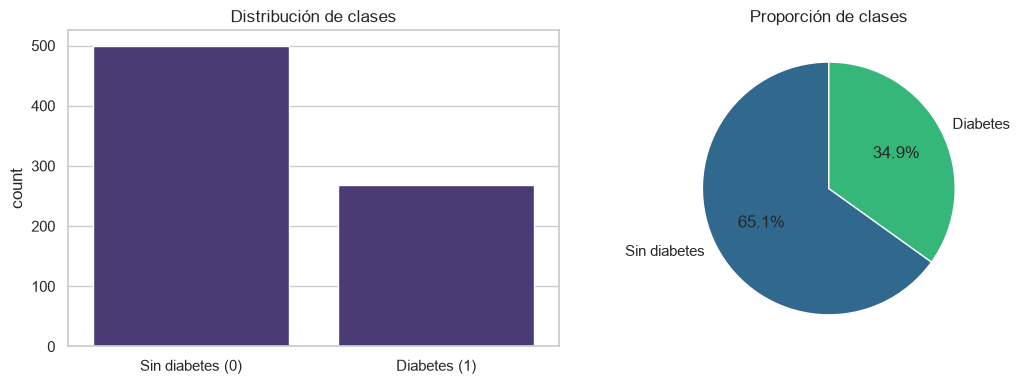

In [5]:
counts = df["Outcome"].value_counts().sort_index()
print(counts)
print(f"Tasa de positivos: {df['Outcome'].mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x="Outcome", data=df, ax=axes[0])
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Sin diabetes (0)", "Diabetes (1)"])
axes[0].set_title("Distribución de clases")
axes[0].set_xlabel("")

axes[1].pie(counts, labels=["Sin diabetes", "Diabetes"], autopct="%1.1f%%",
            colors=sns.color_palette("viridis", 2), startangle=90)
axes[1].set_title("Proporción de clases")
plt.tight_layout()
plt.show()

### 4.2 Valores faltantes escondidos como ceros

No hay valores `NaN`, pero varias columnas contienen **ceros que son biológicamente imposibles** (una persona viva no puede tener 0 de glucosa, 0 de presión arterial ni 0 de IMC). En este dataset un cero significa *"no medido"*, así que debemos tratar esos ceros como datos faltantes.

In [6]:
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = (df[zero_as_missing] == 0).sum().sort_values(ascending=False)

missing_table = pd.DataFrame({
    "ceros (tratados como faltantes)": zero_counts,
    "porcentaje": (zero_counts / len(df) * 100).round(1),
})
missing_table["porcentaje"] = missing_table["porcentaje"].astype(str) + " %"
missing_table

,ceros (tratados como faltantes),porcentaje
Insulin,374,48.7 %
SkinThickness,227,29.6 %
BloodPressure,35,4.6 %
BMI,11,1.4 %
Glucose,5,0.7 %


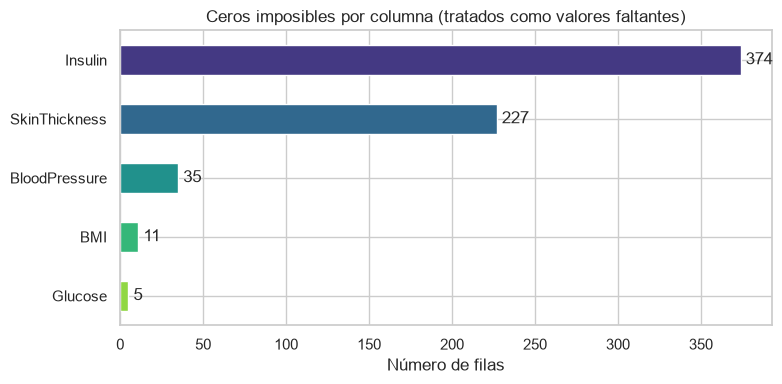

In [7]:
ax = zero_counts.plot(kind="barh", figsize=(8, 4), color=sns.color_palette("viridis", len(zero_counts)))
ax.set_title("Ceros imposibles por columna (tratados como valores faltantes)")
ax.set_xlabel("Número de filas")
ax.invert_yaxis()
for i, value in enumerate(zero_counts.values):
    ax.text(value + 3, i, str(value), va="center")
plt.tight_layout()
plt.show()

### 4.3 Distribución de las características

Los histogramas muestran la forma de cada característica. `Glucose`, `BMI` y `Age` ya se ven diferentes entre las dos clases, lo cual es una buena señal para el modelo.

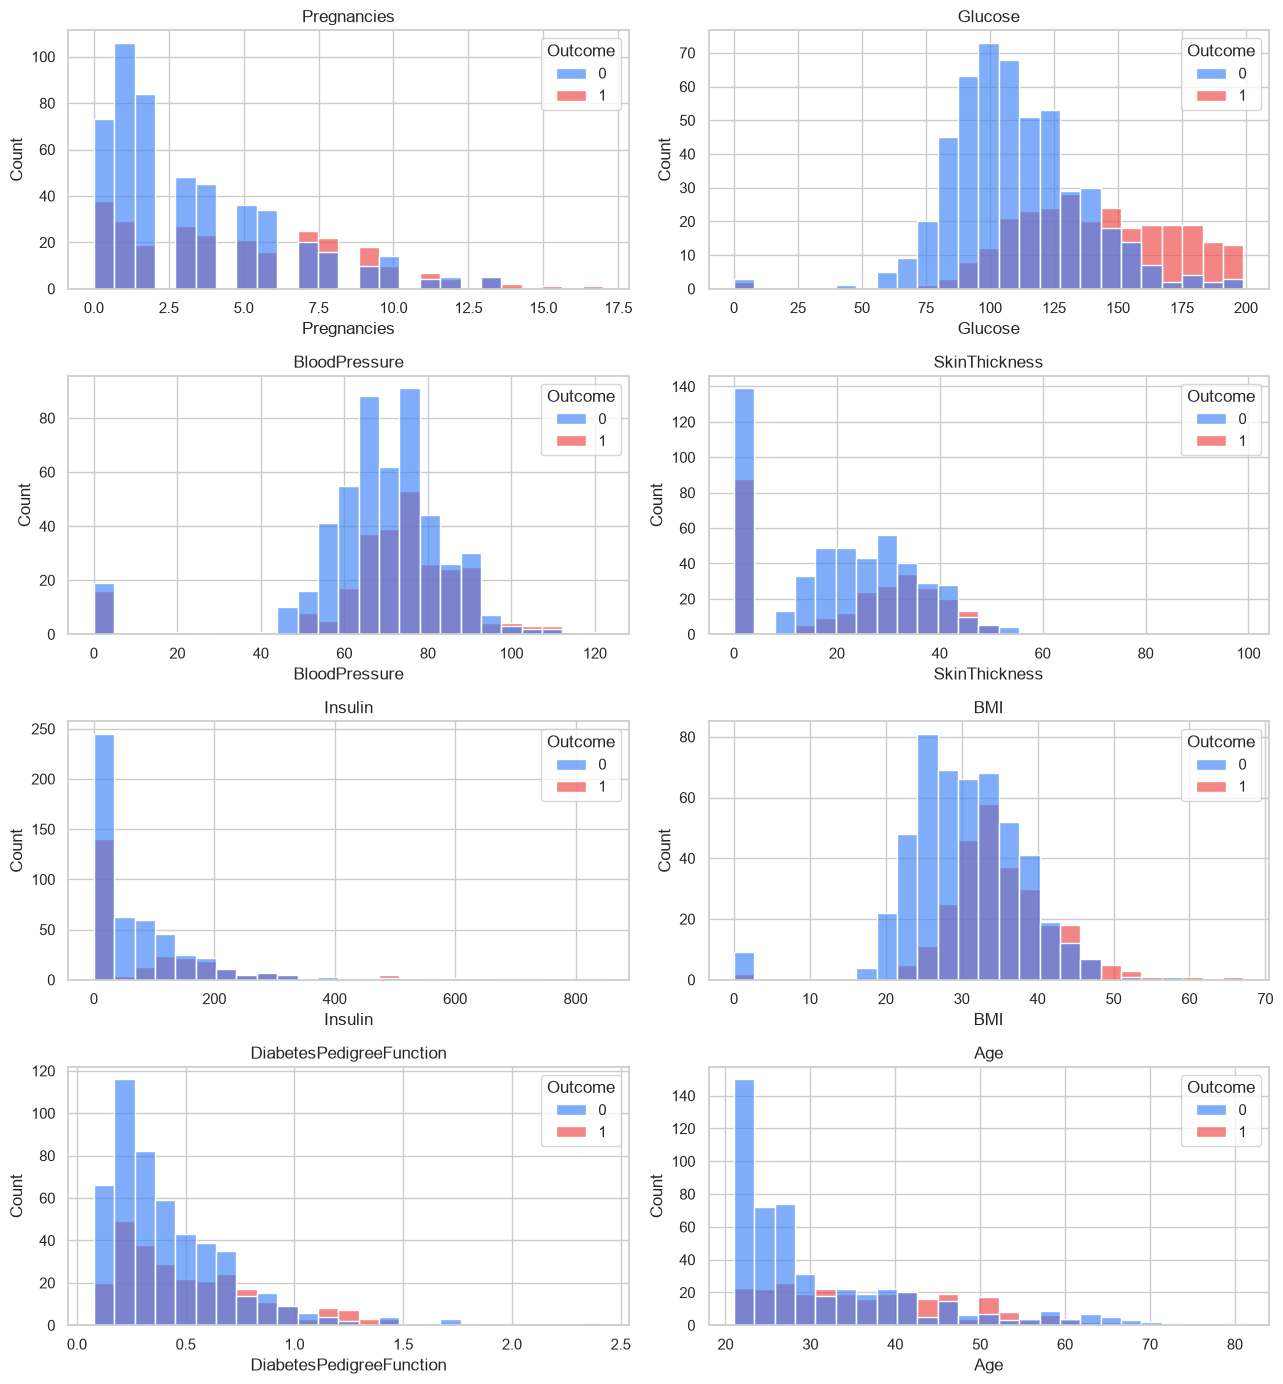

In [8]:
features = [c for c in df.columns if c != "Outcome"]

fig, axes = plt.subplots(4, 2, figsize=(13, 14))
for ax, column in zip(axes.ravel(), features):
    sns.histplot(data=df, x=column, hue="Outcome", bins=25,
                 palette={0: "#3b82f6", 1: "#ef4444"}, alpha=0.65, ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

### 4.4 Relación con la variable objetivo

Los diagramas de caja facilitan ver la separación entre clases. Glucosa e IMC son las características que más separan a los dos grupos.

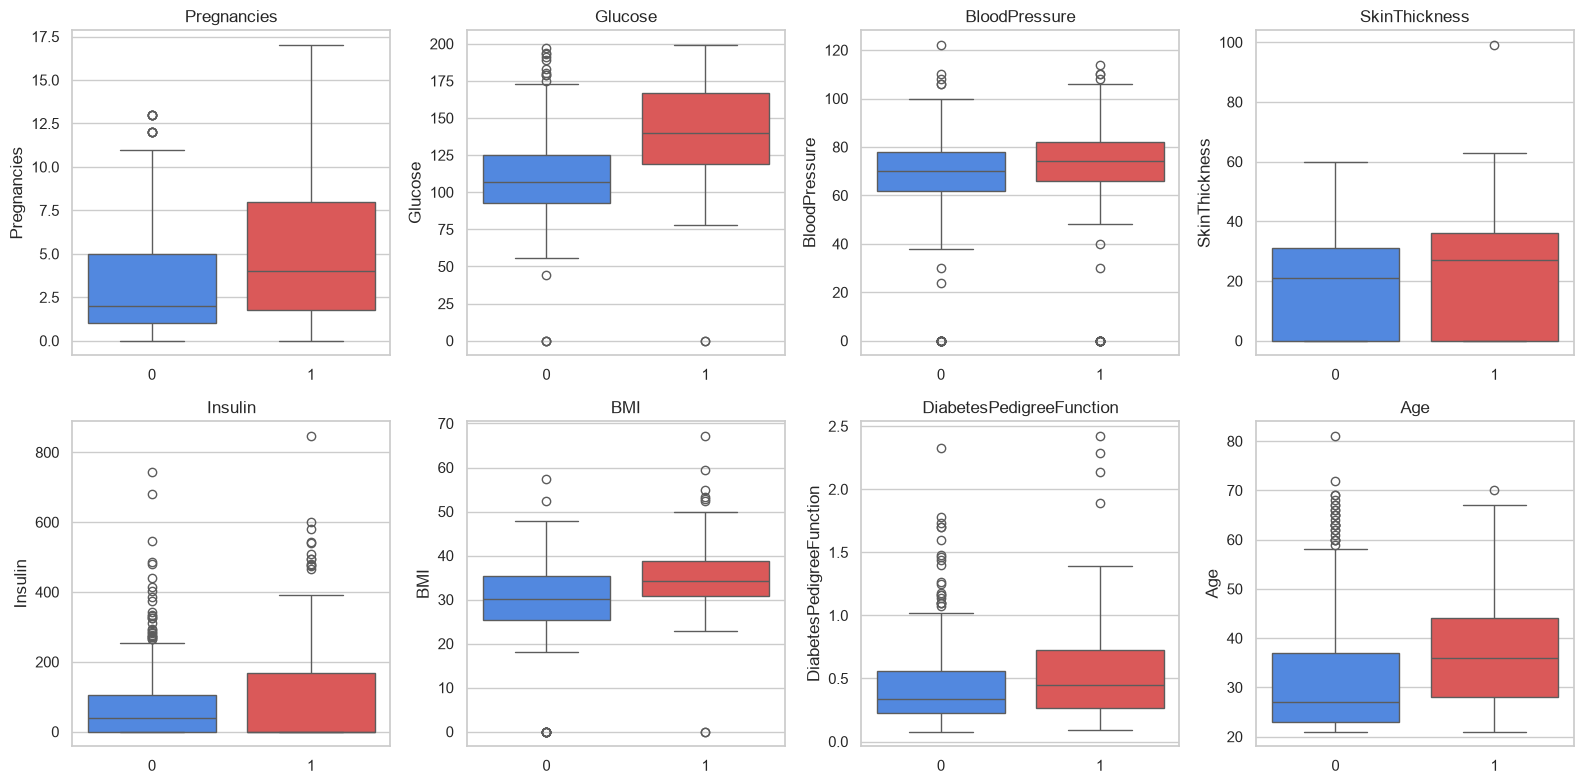

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, column in zip(axes.ravel(), features):
    sns.boxplot(data=df, x="Outcome", y=column, hue="Outcome",
                palette=["#3b82f6", "#ef4444"], legend=False, ax=ax)
    ax.set_title(column)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

### 4.5 Análisis de correlación

`Glucose` es la característica más correlacionada con la diabetes, seguida por `BMI` y `Age`. `SkinThickness` e `Insulin` están fuertemente correlacionadas entre sí, lo que tiene sentido porque ambas miden señales metabólicas relacionadas.

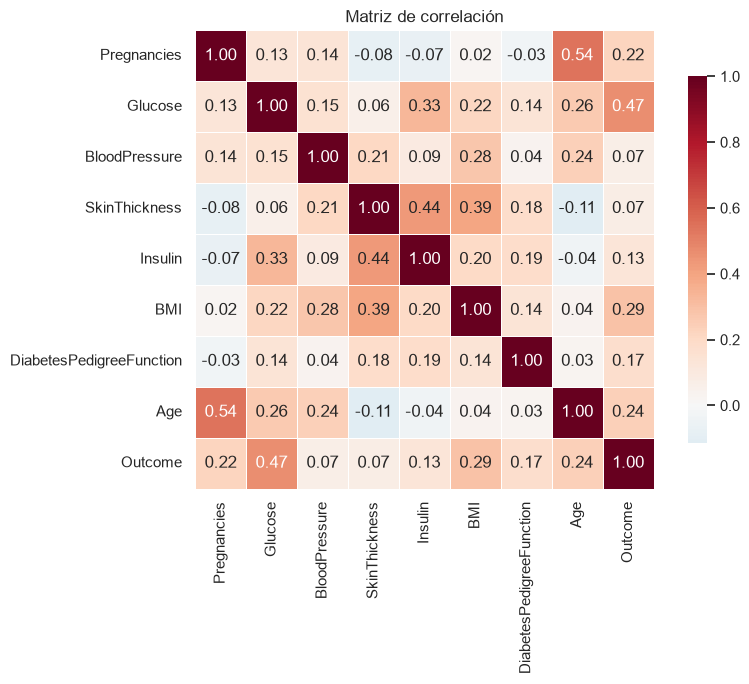

In [10]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

In [11]:
corr["Outcome"].drop("Outcome").sort_values(ascending=False).round(3)

Glucose                     0.467
BMI                         0.293
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
Insulin                     0.131
SkinThickness               0.075
BloodPressure               0.065
Name: Outcome, dtype: float64

### 4.6 Hallazgos clave del EDA

1. **No hay valores faltantes explícitos**, pero 5 columnas contienen ceros imposibles que deben imputarse (hasta 49% de `Insulin`).
2. **Desbalance moderado de clases** (65% / 35%). Usaremos `ROC AUC` y `recall` en lugar de solo la exactitud.
3. **Glucose, BMI, Age y Pregnancies** son las características más correlacionadas con la variable objetivo.
4. Las escalas son muy distintas (la insulina llega a ~850, la función de pedigrí está por debajo de 2.5), por lo que el escalado es necesario para el modelo lineal.

## 5. Limpieza de datos y división entrenamiento/prueba

Siguiendo el hallazgo anterior, los ceros se reemplazan por `NaN` y se imputarán con la **mediana del conjunto de entrenamiento** dentro del pipeline del modelo (así se evita la fuga de datos).

Reservamos el 20% de los datos como conjunto de prueba final que el modelo nunca ve durante el entrenamiento.

In [12]:
df_clean = df.copy()
df_clean[zero_as_missing] = df_clean[zero_as_missing].replace(0, np.nan)

print("Valores faltantes después de reemplazar los ceros:")
print(df_clean[zero_as_missing].isna().sum())

X = df_clean[features]
y = df_clean["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"\nEntrenamiento: {X_train.shape} | Prueba: {X_test.shape}")
print(f"Tasa de positivos en entrenamiento: {y_train.mean():.2%} | en prueba: {y_test.mean():.2%}")

Valores faltantes después de reemplazar los ceros:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Entrenamiento: (614, 8) | Prueba: (154, 8)
Tasa de positivos en entrenamiento: 34.85% | en prueba: 35.06%


## 6. Pipeline de preprocesamiento

Todos los modelos candidatos usan el mismo pipeline:

1. **Imputación por mediana** para los valores faltantes.
2. **Escalado estándar** para que todas las características tengan media 0 y desviación estándar 1.

Usar un `Pipeline` garantiza que el imputador y el escalador se ajusten solo con los datos de entrenamiento, y permite guardar todo el objeto en un solo archivo.

In [13]:
def build_pipeline(estimator):
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", estimator),
    ])

build_pipeline(LogisticRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto accou

## 7. Comparación de modelos con validación cruzada

Comparamos tres modelos con validación cruzada estratificada de 5 pliegues, usando **ROC AUC** como métrica:

* **Regresión Logística** - línea base lineal, fácil de interpretar.
* **Random Forest** - no lineal, robusto a valores atípicos.
* **Gradient Boosting** - no lineal, suele ser muy fuerte en datos tabulares.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "Regresión Logística": build_pipeline(
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    "Random Forest": build_pipeline(
        RandomForestClassifier(random_state=RANDOM_STATE)),
    "Gradient Boosting": build_pipeline(
        GradientBoostingClassifier(random_state=RANDOM_STATE)),
}

cv_scores = {}
for name, model in candidates.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_scores[name] = scores
    print(f"{name:22s} ROC AUC = {scores.mean():.4f} +/- {scores.std():.4f}")

Regresión Logística    ROC AUC = 0.8434 +/- 0.0185


Random Forest          ROC AUC = 0.8154 +/- 0.0230


Gradient Boosting      ROC AUC = 0.8206 +/- 0.0155


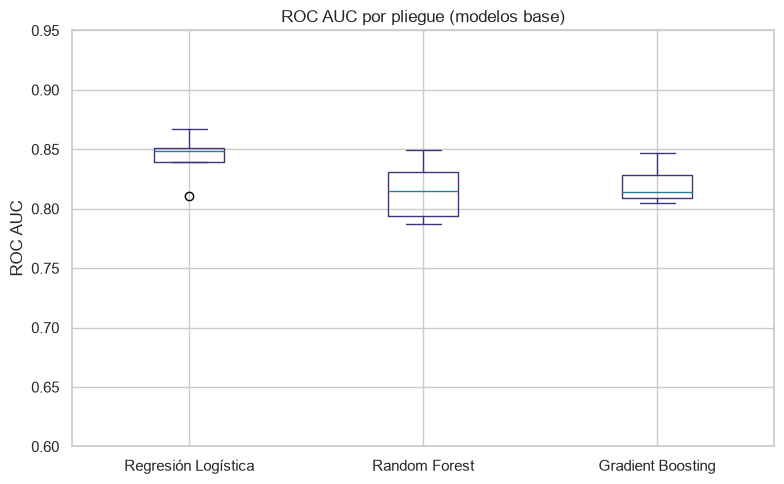

In [15]:
pd.DataFrame(cv_scores).plot(kind="box", figsize=(8, 5), title="ROC AUC por pliegue (modelos base)")
plt.ylabel("ROC AUC")
plt.ylim(0.6, 0.95)
plt.tight_layout()
plt.show()

## 8. Ajuste de hiperparámetros

Ahora ajustamos cada modelo con `GridSearchCV` (5 pliegues, ROC AUC). También probamos `class_weight="balanced"` en los dos modelos que lo soportan, porque las clases están desbalanceadas y dejar pasar a un paciente enfermo (falso negativo) cuesta más que una falsa alarma.

In [16]:
param_grids = {
    "Regresión Logística": {
        "classifier__C": [0.01, 0.1, 1.0, 10.0],
        "classifier__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "classifier__n_estimators": [200, 400],
        "classifier__max_depth": [None, 4, 8],
        "classifier__min_samples_leaf": [1, 3],
        "classifier__class_weight": [None, "balanced"],
    },
    "Gradient Boosting": {
        "classifier__n_estimators": [100, 200],
        "classifier__learning_rate": [0.05, 0.1],
        "classifier__max_depth": [2, 3],
    },
}

searches = {}
for name, model in candidates.items():
    print(f"Ajustando {name}...")
    search = GridSearchCV(model, param_grids[name], cv=cv, scoring="roc_auc", n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    searches[name] = search
    print(f"  mejor ROC AUC en CV: {search.best_score_:.4f}")
    print(f"  mejores parámetros: {search.best_params_}")

Ajustando Regresión Logística...


  mejor ROC AUC en CV: 0.8450
  mejores parámetros: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Ajustando Random Forest...


  mejor ROC AUC en CV: 0.8389
  mejores parámetros: {'classifier__class_weight': None, 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 3, 'classifier__n_estimators': 400}
Ajustando Gradient Boosting...


  mejor ROC AUC en CV: 0.8297
  mejores parámetros: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__n_estimators': 100}


## 9. Evaluación final sobre el conjunto de prueba

El conjunto de prueba nunca se usó para entrenar ni para ajustar. Tomamos el modelo con el mejor puntaje de validación cruzada y lo evaluamos una sola vez sobre el conjunto de prueba.

In [17]:
best_name = max(searches, key=lambda name: searches[name].best_score_)
best_model = searches[best_name].best_estimator_
print(f"Mejor modelo: {best_name} (ROC AUC en CV = {searches[best_name].best_score_:.4f})")

y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, target_names=["Sin diabetes", "Diabetes"], digits=4))
print(f"ROC AUC en el conjunto de prueba: {roc_auc_score(y_test, y_proba):.4f}")

Mejor modelo: Regresión Logística (ROC AUC en CV = 0.8450)

Reporte de clasificación:
              precision    recall  f1-score   support

Sin diabetes     0.8022    0.7300    0.7644       100
    Diabetes     0.5714    0.6667    0.6154        54

    accuracy                         0.7078       154
   macro avg     0.6868    0.6983    0.6899       154
weighted avg     0.7213    0.7078    0.7121       154

ROC AUC en el conjunto de prueba: 0.8104


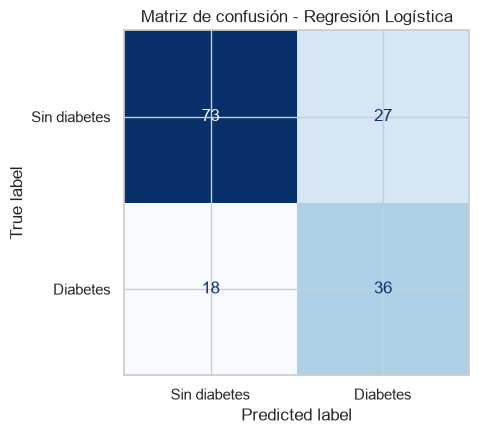

In [18]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Sin diabetes", "Diabetes"],
    cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"Matriz de confusión - {best_name}")
plt.tight_layout()
plt.show()

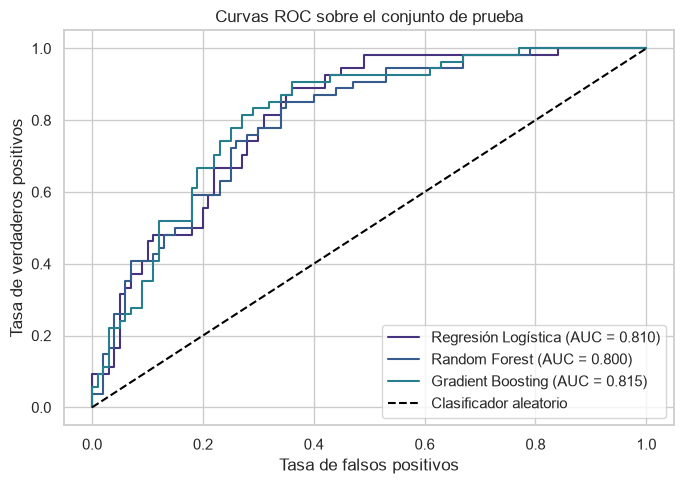

In [19]:
plt.figure(figsize=(7, 5))
for name, search in searches.items():
    proba = search.best_estimator_.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Clasificador aleatorio")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curvas ROC sobre el conjunto de prueba")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Importancia de las características e interpretación

Como el modelo seleccionado es una regresión logística, sus coeficientes indican la dirección de cada efecto sobre el log-odds de tener diabetes (las características fueron escaladas, así que las magnitudes son comparables).

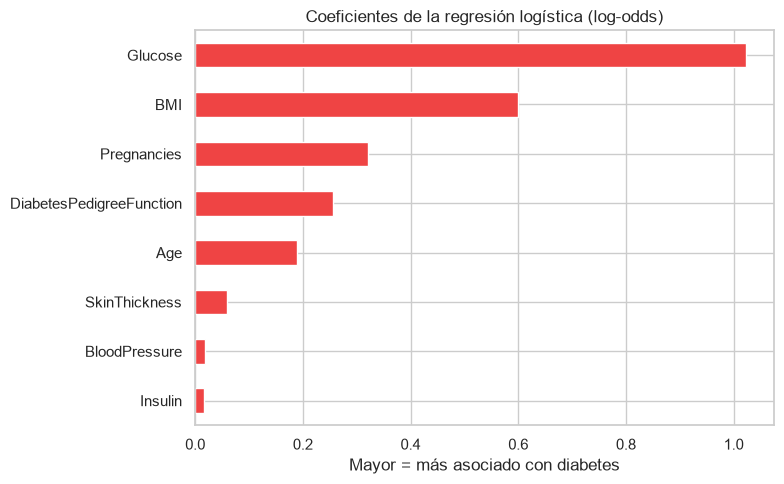

Glucose                     1.024
BMI                         0.599
Pregnancies                 0.321
DiabetesPedigreeFunction    0.256
Age                         0.189
SkinThickness               0.059
BloodPressure               0.017
Insulin                     0.016
dtype: float64

In [20]:
classifier = best_model.named_steps["classifier"]

if hasattr(classifier, "coef_"):
    importance = pd.Series(classifier.coef_[0], index=features).sort_values()
    title = "Coeficientes de la regresión logística (log-odds)"
else:
    importance = pd.Series(classifier.feature_importances_, index=features).sort_values()
    title = "Importancia de las características"

plt.figure(figsize=(8, 5))
colors = ["#ef4444" if value > 0 else "#3b82f6" for value in importance.values]
importance.plot(kind="barh", color=colors)
plt.title(title)
plt.xlabel("Mayor = más asociado con diabetes")
plt.tight_layout()
plt.show()

importance.sort_values(ascending=False).round(3)

**Interpretación:** una mayor glucosa, IMC, edad y número de embarazos aumentan el riesgo estimado, mientras que la función de pedigrí diabético tiene un efecto menor una vez que se consideran las demás variables. Esto coincide con la literatura médica y con el EDA anterior.

## 11. Guardado del modelo final

Guardamos el **pipeline completo** (imputador + escalador + clasificador) junto con la lista de características y las métricas de prueba, para que la API Flask pueda cargar un solo archivo y predecir directamente desde valores crudos.

In [21]:
bundle = {
    "model": best_model,
    "model_name": best_name,
    "features": features,
    "target": "Outcome",
    "threshold": 0.5,
    "test_metrics": {
        "accuracy": round(float((y_pred == y_test).mean()), 4),
        "roc_auc": round(float(roc_auc_score(y_test, y_proba)), 4),
        "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
    },
}

model_path = MODEL_DIR / "diabetes_pipeline.joblib"
joblib.dump(bundle, model_path)
print(f"Guardado en {model_path} ({model_path.stat().st_size / 1024:.1f} KB)")

loaded = joblib.load(model_path)
sample = X_test.iloc[[0]]
print("Predicción del modelo recargado:", loaded["model"].predict_proba(sample)[0, 1].round(4))
print("Etiqueta real:", int(y_test.iloc[0]))

Guardado en model\diabetes_pipeline.joblib (2.5 KB)
Predicción del modelo recargado: 0.7003
Etiqueta real: 0


## 12. Conclusiones

* El dataset necesitó una limpieza cuidadosa: los **ceros no eran mediciones reales** sino valores faltantes.
* Se compararon tres modelos con validación cruzada y todos se ajustaron con `GridSearchCV`.
* La **Regresión Logística** con `class_weight="balanced"` obtuvo el mejor ROC AUC de validación cruzada (~0.845) y un ROC AUC de prueba de ~0.81, un resultado sólido para este dataset pequeño.
* El escalado y la imputación por mediana forman parte del pipeline guardado, así que la API acepta valores clínicos crudos (un cero significa "no medido").
* El modelo se exporta a `train.py`, se sirve con `predict.py` (Flask) y se empaqueta con Docker. Las instrucciones de despliegue están en el README.

**Limitaciones:** el dataset es pequeño (768 filas) e incluye solo mujeres de ascendencia india Pima, por lo que el modelo no debería usarse en otras poblaciones sin reentrenarlo. Es una ayuda al tamizaje, no un diagnóstico médico.